# Lluvias: serie diaria y años hidrológicos

Lee la serie de precipitación diaria de `data/1083e_R.xls` (empieza el 1 de octubre de 1980)
y dibuja la lluvia diaria, el máximo diario y el acumulado de cada año hidrológico
(de octubre a septiembre).

Usa pandas matplotlib xlrd (todas en `requirements.txt`).

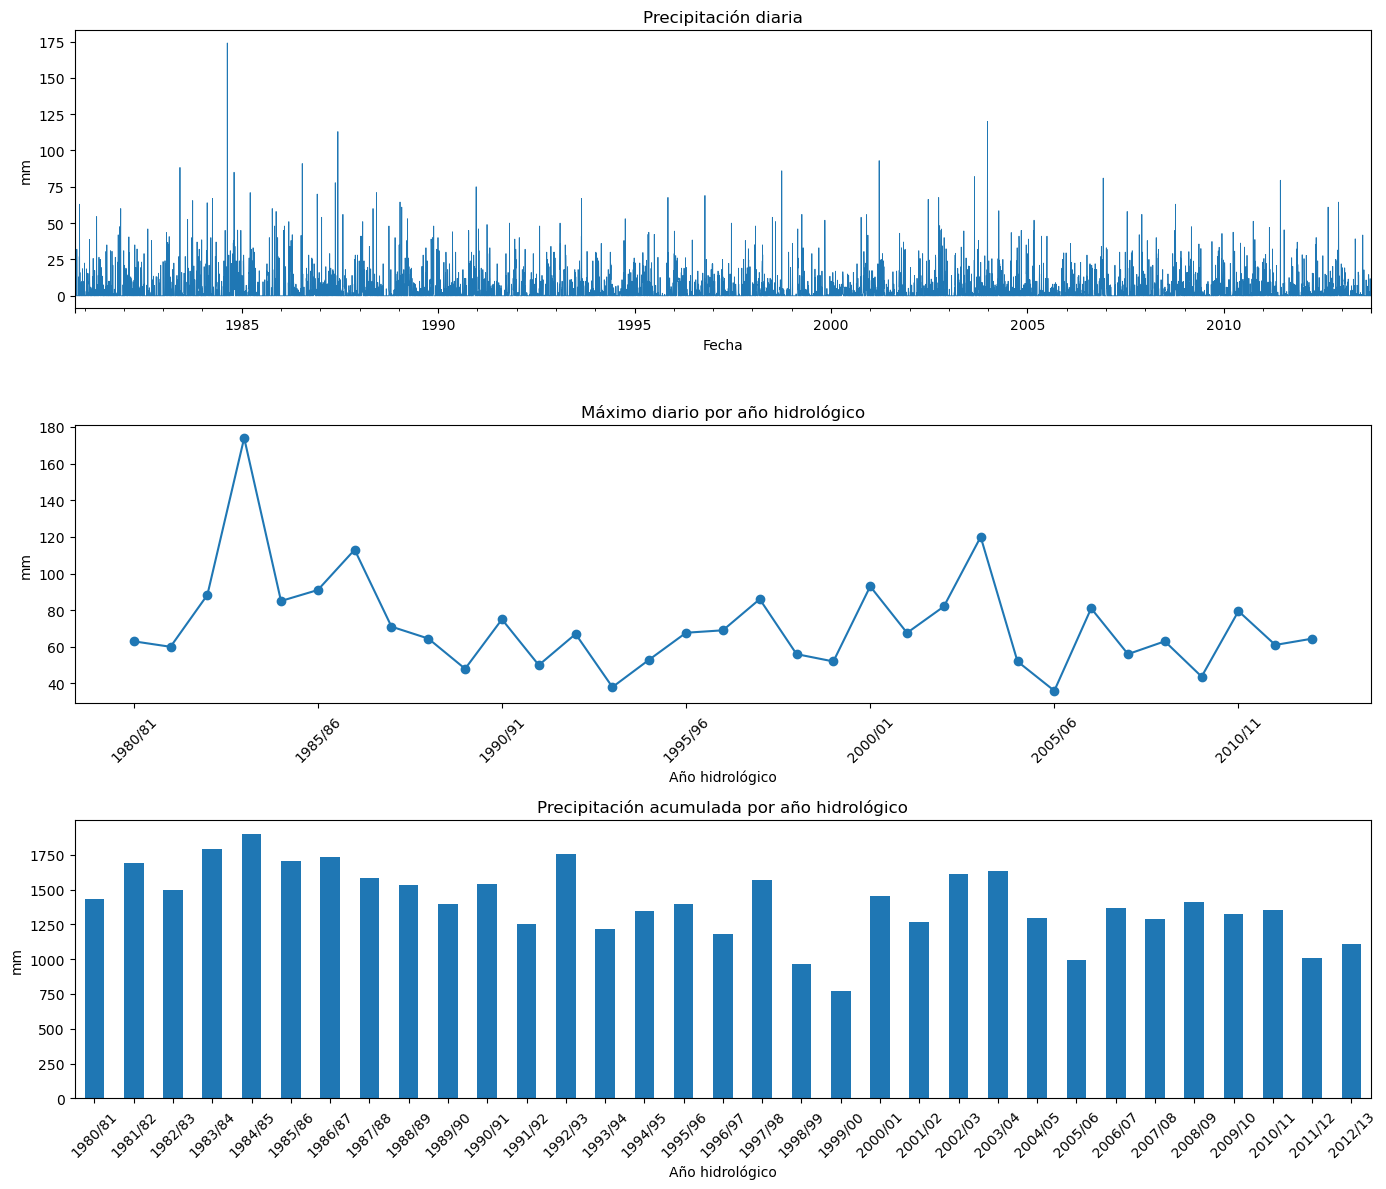

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Datos de precipitación diaria (mm), en la carpeta data/ junto a este notebook.
excel_path = Path("data") / "1083e_R.xls"

# Lee la primera columna, conservando las filas vacías para no desplazar las fechas.
datos = pd.read_excel(excel_path, header=None)
lluvia = pd.to_numeric(datos.iloc[:, 0], errors="coerce")

# Si la primera celda contiene un encabezado, lo excluye.
if pd.notna(datos.iloc[0, 0]) and pd.isna(lluvia.iloc[0]):
    lluvia = lluvia.iloc[1:].reset_index(drop=True)

fechas = pd.date_range("1980-10-01", periods=len(lluvia), freq="D")
serie = pd.Series(lluvia.to_numpy(), index=fechas, name="Precipitación (mm)")
df = serie.to_frame()

# Año hidrológico: empieza en octubre.
anio_inicio = df.index.year - (df.index.month < 10).astype(int)
df["Año hidrológico"] = anio_inicio

maximos = df.groupby("Año hidrológico")["Precipitación (mm)"].max()
acumulados = df.groupby("Año hidrológico")["Precipitación (mm)"].sum(min_count=1)


def etiqueta_hidrologica(anio):
    """Etiqueta del año hidrológico que empieza en octubre de `anio`, p. ej. 1980/81."""
    return f"{anio}/{str(anio + 1)[-2:]}"


maximos.index = [etiqueta_hidrologica(a) for a in maximos.index]
acumulados.index = [etiqueta_hidrologica(a) for a in acumulados.index]

# Gráficos
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

df["Precipitación (mm)"].plot(ax=axes[0], linewidth=0.6)
axes[0].set(title="Precipitación diaria", xlabel="Fecha", ylabel="mm")

maximos.plot(ax=axes[1], marker="o")
axes[1].set(
    title="Máximo diario por año hidrológico", xlabel="Año hidrológico", ylabel="mm"
)
axes[1].tick_params(axis="x", rotation=45)

acumulados.plot(ax=axes[2], kind="bar")
axes[2].set(
    title="Precipitación acumulada por año hidrológico",
    xlabel="Año hidrológico",
    ylabel="mm",
)
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()